# 02 — CTU-13: Kaggle EDA & Label Audit

**Scope:** inventory all 13 CTU-13 scenarios; detailed exploratory analysis for **scenarios 5, 11, 12** (as in the original notebook). Reads existing **Parquet files directly** from Kaggle Input; no ZIP or re-upload required.

**Label policy:** `Background` is **UNKNOWN** (not automatically `Normal`); `From-Normal` / `Normal-` are verified normal; `From-Botnet` represents botnet. Categories not matching these rules remain `UNKNOWN`. This is an EDA label audit, **not a validated binary training split**.

**Data limitation:** supplied 11-column Parquet may lack IP addresses, ports and timestamps. The graph/beaconing preview from the original notebook is therefore **not run unless those fields are actually present**.

## 1. Set up paths and dependencies

In [16]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display

# Use the exact Kaggle mount already observed; fall back to discovery if the slug changes.
PREFERRED = Path('/kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset')
SEARCH_ROOT = Path('/kaggle/input')
if PREFERRED.is_dir():
    CTU_DIR = PREFERRED
else:
    matches = sorted({p.parent for p in SEARCH_ROOT.rglob('*.binetflow.parquet')}) if SEARCH_ROOT.exists() else []
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected one CTU-13 Parquet directory, found: {matches}')
    CTU_DIR = matches[0]

OUTPUT = Path('/kaggle/working/nids_outputs/02_CTU_EDA') if Path('/kaggle/working').exists() else Path('reports/notebook_outputs/02_CTU_EDA')
OUTPUT.mkdir(parents=True, exist_ok=True)
FILES = sorted(CTU_DIR.glob('*.binetflow.parquet'))
assert len(FILES) == 13, f'Expected 13 CTU-13 Parquet files; found {len(FILES)} at {CTU_DIR}'
print('CTU_DIR:', CTU_DIR)
print('OUTPUT:', OUTPUT)
print('Parquet files:', len(FILES))

CTU_DIR: /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset
OUTPUT: /kaggle/working/nids_outputs/02_CTU_EDA
Parquet files: 13


## 2. Inventory all 13 scenarios from Parquet metadata (no full-data load)

In [17]:
inventory = []
for path in FILES:
    match = re.match(r'^(\d+)-', path.name)
    if not match:
        raise ValueError(f'Cannot parse scenario ID from {path.name}')
    pf = pq.ParquetFile(path)
    inventory.append({
        'scenario_id': int(match.group(1)),
        'file': path.name,
        'rows': pf.metadata.num_rows,
        'columns': len(pf.schema.names),
        'size_mb': round(path.stat().st_size / (1024 ** 2), 2),
    })

inventory_df = pd.DataFrame(inventory).sort_values('scenario_id').reset_index(drop=True)
display(inventory_df)
print('All scenarios total flows:', f"{inventory_df['rows'].sum():,}")
print('Column counts:', inventory_df['columns'].unique().tolist())
inventory_df.to_csv(OUTPUT / 'ctu_scenario_inventory.csv', index=False)

,scenario_id,file,rows,columns,size_mb
0,1,1-Neris-20110810.binetflow.parquet,1621173,11,17.01
1,2,2-Neris-20110811.binetflow.parquet,1120229,11,11.95
2,3,3-Rbot-20110812.binetflow.parquet,1853035,11,20.37
3,4,4-Rbot-20110815.binetflow.parquet,702322,11,7.91
4,5,5-Virut-20110815-2.binetflow.parquet,92900,11,1.04
5,6,6-Menti-20110816.binetflow.parquet,353386,11,4.14
6,7,7-Sogou-20110816-2.binetflow.parquet,84273,11,0.97
7,8,8-Murlo-20110816-3.binetflow.parquet,1453832,11,16.14
8,9,9-Neris-20110817.binetflow.parquet,1274632,11,14.19
9,10,10-Rbot-20110818.binetflow.parquet,776097,11,8.91


All scenarios total flows: 10,598,771
Column counts: [11]


## 3. Load the original three scenarios (5, 11, 12) and examine the schema

These three scenarios are the same subset targeted by the original notebook. They **do not represent the entire CTU-13 dataset**.

In [18]:
SCENARIOS = (5, 11, 12)
by_id = {int(re.match(r'^(\d+)-', p.name).group(1)): p for p in FILES}
missing_scenarios = sorted(set(SCENARIOS) - set(by_id))
assert not missing_scenarios, f'Missing scenario IDs: {missing_scenarios}'

frames = []
for sid in SCENARIOS:
    frame = pd.read_parquet(by_id[sid])
    frame.columns = frame.columns.astype(str).str.strip()
    frame['scenario_id'] = sid
    frames.append(frame)

ctu = pd.concat(frames, ignore_index=True)
print('Loaded rows:', f'{len(ctu):,}', '| scenarios:', SCENARIOS)
print('Columns:', ctu.columns.tolist())
display(ctu.head(5))
print('Dtypes:')
display(ctu.dtypes.rename('dtype').to_frame())

Loaded rows: 384,176 | scenarios: (5, 11, 12)
Columns: ['dur', 'proto', 'dir', 'state', 'stos', 'dtos', 'tot_pkts', 'tot_bytes', 'src_bytes', 'label', 'Family', 'scenario_id']


,dur,proto,dir,state,stos,dtos,tot_pkts,tot_bytes,src_bytes,label,Family,scenario_id
0,0.000000,tcp,?>,RA_,0.0,0.0,1,60,60,flow=Background,20110815,5
1,13.431962,tcp,->,SRA_SA,0.0,0.0,6,388,208,flow=Background-TCP-Established,20110815,5
2,13.350228,tcp,->,SRA_SA,0.0,0.0,6,388,208,flow=Background-TCP-Established,20110815,5
3,13.010090,tcp,->,SRA_SA,0.0,0.0,6,388,208,flow=Background-TCP-Established,20110815,5
4,20.990047,tcp,->,SR_SA,0.0,0.0,5,308,122,flow=Background-TCP-Established,20110815,5


Dtypes:


,dtype
dur,float32
proto,object
dir,category
state,object
stos,float32
dtos,float32
tot_pkts,int32
tot_bytes,int32
src_bytes,int32
label,object


## 4. Label audit — keep Background separate from Normal and Botnet

In [19]:
assert 'label' in ctu.columns, f'Missing label column; available: {ctu.columns.tolist()}'
raw_label = ctu['label'].astype('string').str.strip()

def label_group(value):
    if pd.isna(value) or not str(value).strip():
        return 'UNKNOWN'
    s = str(value).strip()
    if s.startswith('flow='):
        s = s[5:]
    s_lower = s.lower()
    if s_lower.startswith('background') or s_lower.startswith('to-background') or s_lower.startswith('from-background'):
        return 'UNKNOWN'
    if s_lower.startswith('from-botnet'):
        return 'BOTNET'
    if s_lower.startswith('from-normal') or s_lower.startswith('normal-'):
        return 'NORMAL'
    return 'UNKNOWN'

ctu['label_group'] = raw_label.map(label_group)
summary = (ctu.groupby(['scenario_id', 'label_group'], dropna=False)
           .size().rename('flows').reset_index()
           .sort_values(['scenario_id', 'label_group']))
print('Verified high-level categories (Background = UNKNOWN):')
display(summary)
print('Overall categories:')
display(ctu['label_group'].value_counts(dropna=False).rename_axis('label_group').reset_index(name='flows'))
print('Most frequent raw labels:')
display(raw_label.value_counts(dropna=False).head(20).rename_axis('raw_label').reset_index(name='flows'))
summary.to_csv(OUTPUT / 'ctu_label_group_counts.csv', index=False)
raw_counts = (ctu.groupby(['scenario_id', 'label'], dropna=False).size()
              .rename('flows').reset_index().sort_values(['scenario_id', 'flows'], ascending=[True, False]))
raw_counts.to_csv(OUTPUT / 'ctu_raw_label_counts.csv', index=False)

Verified high-level categories (Background = UNKNOWN):


,scenario_id,label_group,flows
0,5,BOTNET,880
1,5,NORMAL,4467
2,5,UNKNOWN,87553
3,11,BOTNET,786
4,11,NORMAL,1507
5,11,UNKNOWN,70066
6,12,BOTNET,2000
7,12,NORMAL,6885
8,12,UNKNOWN,210032


Overall categories:


,label_group,flows
0,UNKNOWN,367651
1,NORMAL,12859
2,BOTNET,3666


Most frequent raw labels:


,raw_label,flows
0,flow=Background-UDP-Established,132729
1,flow=To-Background-UDP-CVUT-DNS-Server,89357
2,flow=Background-TCP-Established,63850
3,flow=Background-Established-cmpgw-CVUT,41880
4,flow=Background,9484
5,flow=Background-UDP-Attempt,8809
6,flow=To-Background-CVUT-Proxy,6468
7,flow=Background-TCP-Attempt,5239
8,flow=Background-Attempt-cmpgw-CVUT,4571
9,flow=From-Normal-V53-Stribrek,3646


## 5. Data quality audit and numeric feature ranges

In [20]:
expected_numeric = ['dur', 'stos', 'dtos', 'tot_pkts', 'tot_bytes', 'src_bytes']
numeric_cols = [c for c in expected_numeric if c in ctu.columns]
quality = []
for name in ctu.columns:
    col = ctu[name]
    record = {'column': name, 'dtype': str(col.dtype), 'nulls': int(col.isna().sum()),
              'null_pct': round(float(col.isna().mean() * 100), 4)}
    if name in numeric_cols:
        values = pd.to_numeric(col, errors='coerce')
        record['non_numeric_or_null'] = int(values.isna().sum())
        record['infinite'] = int(np.isinf(values.to_numpy(dtype=float, na_value=np.nan)).sum())
    quality.append(record)
quality_df = pd.DataFrame(quality)
display(quality_df)
quality_df.to_csv(OUTPUT / 'ctu_quality_summary.csv', index=False)

print('Duplicate rows across original columns (within selected scenarios):',
      int(ctu.drop(columns=['label_group', 'scenario_id'], errors='ignore').duplicated().sum()))
if numeric_cols:
    safe_numeric = ctu[numeric_cols].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    display(safe_numeric.describe(percentiles=[.5, .9, .99]).T)
    safe_numeric.describe(percentiles=[.5, .9, .99]).T.to_csv(OUTPUT / 'ctu_numeric_describe.csv')

,column,dtype,nulls,null_pct,non_numeric_or_null,infinite
0,dur,float32,0,0.0000,0.0,0.0
1,proto,object,0,0.0000,NaN,NaN
2,dir,category,0,0.0000,NaN,NaN
3,state,object,3,0.0008,NaN,NaN
4,stos,float32,2725,0.7093,2725.0,0.0
5,dtos,float32,22473,5.8497,22473.0,0.0
6,tot_pkts,int32,0,0.0000,0.0,0.0
7,tot_bytes,int32,0,0.0000,0.0,0.0
8,src_bytes,int32,0,0.0000,0.0,0.0
9,label,object,0,0.0000,NaN,NaN


Duplicate rows across original columns (within selected scenarios): 0


,count,mean,std,min,50%,90%,99%,max
dur,384176.0,221.193726,6.677162e+02,0.0,0.148555,618.088104,3304.203247,3600.0
stos,381451.0,0.007401,1.033370e+00,0.0,0.000000,0.000000,0.000000,192.0
dtos,361703.0,0.000832,4.591405e-02,0.0,0.000000,0.000000,0.000000,3.0
tot_pkts,384176.0,56.630565,3.672322e+03,1.0,2.000000,27.000000,264.000000,1491594.0
tot_bytes,384176.0,41192.490785,2.910240e+06,60.0,470.000000,9302.000000,163464.500000,853704136.0
src_bytes,384176.0,7856.385605,7.977259e+05,0.0,157.000000,2111.000000,20148.500000,345277691.0


## 6. Figures — scenario volumes and label proportions

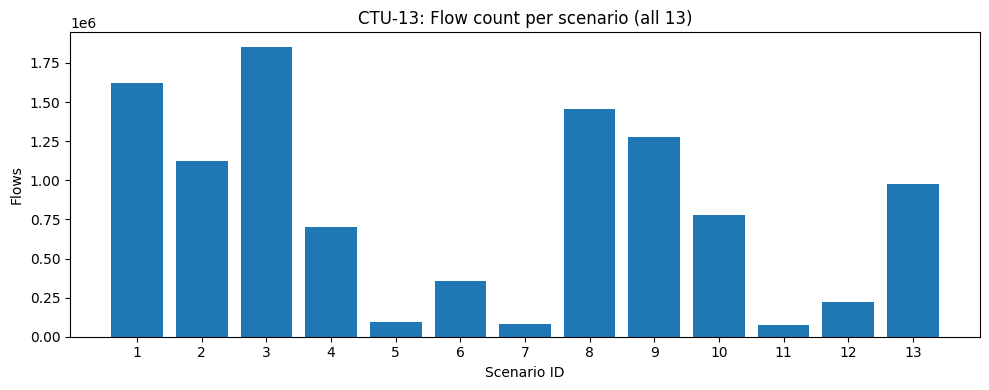

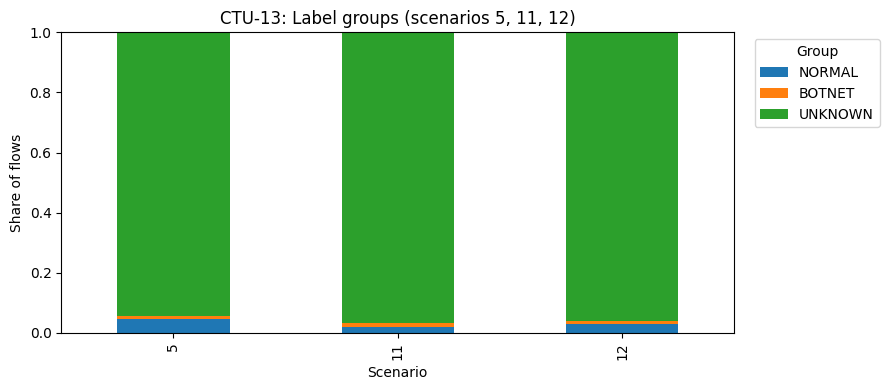

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(inventory_df['scenario_id'].astype(str), inventory_df['rows'])
ax.set(title='CTU-13: Flow count per scenario (all 13)', xlabel='Scenario ID', ylabel='Flows')
fig.tight_layout()
fig.savefig(OUTPUT / 'ctu_all_scenario_sizes.png', dpi=160)
plt.show()

pivot = (summary.pivot(index='scenario_id', columns='label_group', values='flows')
         .fillna(0).reindex(columns=['NORMAL', 'BOTNET', 'UNKNOWN'], fill_value=0))
fractions = pivot.div(pivot.sum(axis=1), axis=0)
ax = fractions.plot(kind='bar', stacked=True, figsize=(9, 4))
ax.set(title='CTU-13: Label groups (scenarios 5, 11, 12)', xlabel='Scenario', ylabel='Share of flows', ylim=(0, 1))
ax.legend(title='Group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT / 'ctu_label_groups_selected.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Graph / beaconing readiness check — no invented topology

Graph-based communication and beaconing require **source/destination host IDs** and **timestamps**. The dataset currently mounted in Kaggle was observed to contain 11 columns without these fields. This cell explicitly checks availability and does **not** fabricate a graph or temporal patterns.

In [22]:
available = {c.lower().replace(' ', '').replace('_', ''): c for c in ctu.columns}
def first_present(candidates):
    return next((available[k] for k in candidates if k in available), None)

required = {
    'src_ip': first_present(['srcaddr', 'srcip', 'sourceip']),
    'dst_ip': first_present(['dstaddr', 'dstip', 'destinationip']),
    'timestamp': first_present(['starttime', 'timestamp', 'time', 'ts']),
}
print('Graph/beaconing required fields:', required)
ready = all(required.values())
print('Graph/beaconing feasible from these files:', ready)
if not ready:
    print('SKIPPED: cannot infer per-host communication graphs or temporal beaconing without IPs and timestamps.')
(OUTPUT / 'ctu_graph_readiness.json').write_text(json.dumps({
    'scenarios': list(SCENARIOS), 'present_columns': ctu.columns.tolist(),
    'required_columns': required, 'graph_beaconing_ready': ready,
    'note': 'Graph/beaconing not executed without src/dst IP and timestamp.'
}, indent=2))

Graph/beaconing required fields: {'src_ip': None, 'dst_ip': None, 'timestamp': None}
Graph/beaconing feasible from these files: False
SKIPPED: cannot infer per-host communication graphs or temporal beaconing without IPs and timestamps.


461

## 8. Save EDA summary and list artifacts

In [23]:
eda_summary = {
    'dataset': 'CTU-13 Kaggle Parquet',
    'all_scenarios': int(len(inventory_df)),
    'all_scenarios_rows': int(inventory_df['rows'].sum()),
    'detailed_scenarios': list(SCENARIOS),
    'detailed_rows': int(len(ctu)),
    'label_policy': 'Background and unrecognized labels are UNKNOWN (not Normal)',
    'label_group_counts': {str(k): int(v) for k, v in ctu['label_group'].value_counts().items()},
    'columns': list(ctu.columns),
    'graph_beaconing_ready': bool(ready),
}
(OUTPUT / 'ctu_eda_summary.json').write_text(json.dumps(eda_summary, indent=2))
print('EDA saved to:', OUTPUT)
for p in sorted(OUTPUT.iterdir()):
    print('-', p.name, f'({p.stat().st_size:,} bytes)')

EDA saved to: /kaggle/working/nids_outputs/02_CTU_EDA
- ctu_all_scenario_sizes.png (35,192 bytes)
- ctu_eda_summary.json (592 bytes)
- ctu_graph_readiness.json (461 bytes)
- ctu_label_group_counts.csv (167 bytes)
- ctu_label_groups_selected.png (36,071 bytes)
- ctu_numeric_describe.csv (575 bytes)
- ctu_quality_summary.csv (408 bytes)
- ctu_raw_label_counts.csv (8,984 bytes)
- ctu_scenario_inventory.csv (737 bytes)
